In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
df_test = pd.read_csv('/Users/fbed874/Desktop/MB5_pilot_ManyBabies5_2026-11-06_09h52.09.380.csv')
df_test.head()

/var/folders/dm/sbdv31d55_3000ql2l05ttm5pl5dqc/T/ipykernel_34303/3900335799.py:1: DtypeWarning: Columns (0: key_resp_continue_baby_video.keys, 1: piloting, 2: key_resp_start.keys, 3: pause_loop.key_resp_continue_baby_video.keys) have mixed types. Specify dtype option on import or set low_memory=False.
  df_test = pd.read_csv('/Users/fbed874/Desktop/MB5_pilot_ManyBabies5_2026-11-06_09h52.09.380.csv')


,trial_number,familiar_stimulus,novel_stimulus,familiar_stimulus_item,novel_stimulus_item,complexity_condition,familiarization_time,familiar_stimulus_path,novel_stimulus_path,familiar_location_1,...,Stop_ET.stopped,participant,order_number,date,expName,expVersion,psychopyVersion,frameRate,expStart,Unnamed: 145
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,MB5_pilot,1,2026-11-06_09h52.22.843,ManyBabies5,NaN,2026.2.5,59.979223,2026-11-06 09h52.23.370841 +1300,NaN
1,1.0,Pyramid_Simple,Bowtie_Simple,Pyramid,Bowtie,simple,5.0,stimuli/images/Pyramid_Simple.png,stimuli/images/Bowtie_Simple.png,left,...,NaN,MB5_pilot,1,2026-11-06_09h52.22.843,ManyBabies5,NaN,2026.2.5,59.979223,2026-11-06 09h52.23.370841 +1300,NaN
2,1.0,Pyramid_Simple,Bowtie_Simple,Pyramid,Bowtie,simple,5.0,stimuli/images/Pyramid_Simple.png,stimuli/images/Bowtie_Simple.png,left,...,NaN,MB5_pilot,1,2026-11-06_09h52.22.843,ManyBabies5,NaN,2026.2.5,59.979223,2026-11-06 09h52.23.370841 +1300,NaN
3,1.0,Pyramid_Simple,Bowtie_Simple,Pyramid,Bowtie,simple,5.0,stimuli/images/Pyramid_Simple.png,stimuli/images/Bowtie_Simple.png,left,...,NaN,MB5_pilot,1,2026-11-06_09h52.22.843,ManyBabies5,NaN,2026.2.5,59.979223,2026-11-06 09h52.23.370841 +1300,NaN
4,1.0,Pyramid_Simple,Bowtie_Simple,Pyramid,Bowtie,simple,5.0,stimuli/images/Pyramid_Simple.png,stimuli/images/Bowtie_Simple.png,left,...,NaN,MB5_pilot,1,2026-11-06_09h52.22.843,ManyBabies5,NaN,2026.2.5,59.979223,2026-11-06 09h52.23.370841 +1300,NaN


# relevant columns for data check

- trial_number
>
- familiarization_time = 5,10,15 seconds
- familiarization_time_timeout = 10,20,30 seconds
>
- gaze_x = x coordinate gaze converted to psychopy units
- gaze_y = y coordingate gaze converted to psychopy units
>
- Familiarization.started = singel time point value
- gaze_time_ROI_familiarization = accumulated looking time to familiarization images
>
- Test_Period.started = singel time point value
- gaze_in_roi_right = binary 0/1 if gaze in ROI
- gaze_time_in_roi_right = accumulated looking time to right test image
- gaze_in_roi_left = binary 0/1 if gaze in ROI
- gaze_time_in_roi_left = accumulated looking time to left test image

In [37]:
# Trial-level summary for familiarization and the two test periods

def last_non_null(series):
    s = series.dropna()
    return s.iloc[-1] if len(s) else np.nan


def first_non_null(series):
    s = series.dropna()
    return s.iloc[0] if len(s) else np.nan


df_work = df_test.copy().reset_index(drop=True)

# Identify test period index (1, 2) inside each trial from Test_Period.started markers
# Label rows by test period using each period's own start/stop markers (bounded within the trial)
df_work['test_period_num'] = 0
for trial, grp in df_work.groupby('trial_number'):
    for period in (1, 2):
        start = grp.index[grp[f'Test_Event_{period}.started'].notna()]
        stop = grp.index[grp[f'Test_Event_{period}.stopped'].notna()]
        if len(start) and len(stop):
            df_work.loc[start[0]:stop[0], 'test_period_num'] = period

# Familiarization summary (one row per trial)
fam_summary = (
    df_work.groupby('trial_number', as_index=False)
    .agg(
        familiarization_time=('familiarization_time', 'first'),
        familiarization_time_timeout=('familiarization_time_timeout', 'first'),
        _fam_started=('Familiarization.started', first_non_null),
        _fam_stopped=('Familiarization.stopped', first_non_null),
        gaze_time_ROI_familiarization_last=('gaze_time_ROI_familiarization', last_non_null),
    )
)

# Duration of familiarization period based on explicit start/stop timestamps
fam_summary['Fam_Duration'] = fam_summary['_fam_stopped'] - fam_summary['_fam_started']
fam_summary = fam_summary.drop(columns=['_fam_started', '_fam_stopped'])

# Test period summary (rows for period 1 and 2 in each trial)
test_rows = df_work[df_work['test_period_num'].between(1, 2)].copy()

for col in ['gaze_in_roi_left_test_1', 'gaze_in_roi_right_test_1', 'gaze_in_roi_left_test_2', 'gaze_in_roi_right_test_2']:
    test_rows[col] = pd.to_numeric(test_rows[col], errors='coerce').fillna(0)

test_summary_long = (
    test_rows.groupby(['trial_number', 'test_period_num'], as_index=False)
    .agg(
        gaze_in_roi_left_count1=('gaze_in_roi_left_test_1', 'sum'),
        gaze_in_roi_right_count1=('gaze_in_roi_right_test_1', 'sum'),
        gaze_time_in_roi_left_last1=('gaze_time_in_roi_left_test_1', last_non_null),
        gaze_time_in_roi_right_last1=('gaze_time_in_roi_right_test_1', last_non_null),
        gaze_in_roi_left_count2=('gaze_in_roi_left_test_2', 'sum'),
        gaze_in_roi_right_count2=('gaze_in_roi_right_test_2', 'sum'),
        gaze_time_in_roi_left_last2=('gaze_time_in_roi_left_test_2', last_non_null),
        gaze_time_in_roi_right_last2=('gaze_time_in_roi_right_test_2', last_non_null),
    )
)

# Convert to wide format: separate columns for test period 1 and 2
test_summary_wide = test_summary_long.pivot(index='trial_number', columns='test_period_num')
test_summary_wide.columns = [f'{metric}_test{int(period)}' for metric, period in test_summary_wide.columns]
test_summary_wide = test_summary_wide.reset_index()

trial_summary = fam_summary.merge(test_summary_wide, on='trial_number', how='left').sort_values('trial_number')

print(f"Trials in summary: {trial_summary['trial_number'].nunique()}")
trial_summary

Trials in summary: 12


,trial_number,familiarization_time,familiarization_time_timeout,gaze_time_ROI_familiarization_last,Fam_Duration,gaze_in_roi_left_count1_test1,gaze_in_roi_left_count1_test2,gaze_in_roi_right_count1_test1,gaze_in_roi_right_count1_test2,gaze_time_in_roi_left_last1_test1,...,gaze_time_in_roi_right_last1_test1,gaze_time_in_roi_right_last1_test2,gaze_in_roi_left_count2_test1,gaze_in_roi_left_count2_test2,gaze_in_roi_right_count2_test1,gaze_in_roi_right_count2_test2,gaze_time_in_roi_left_last2_test1,gaze_time_in_roi_left_last2_test2,gaze_time_in_roi_right_last2_test1,gaze_time_in_roi_right_last2_test2
0,1.0,5.0,10.0,3.299973,9.975572,55.0,0.0,215.0,0.0,0.916727,...,3.316711,NaN,0.0,132.0,0.0,75.0,NaN,2.200032,NaN,1.249982
1,2.0,10.0,20.0,6.963820,19.997793,62.0,0.0,195.0,0.0,1.033362,...,2.066594,NaN,0.0,98.0,0.0,178.0,NaN,1.300141,NaN,2.966554
2,3.0,15.0,30.0,3.100135,29.999291,64.0,0.0,21.0,0.0,1.066669,...,0.349974,NaN,0.0,0.0,0.0,0.0,NaN,0.000000,NaN,0.000000
3,4.0,5.0,10.0,5.008946,5.009628,0.0,0.0,9.0,0.0,0.000000,...,0.149994,NaN,0.0,249.0,0.0,3.0,NaN,0.399949,NaN,0.050023
4,5.0,10.0,20.0,5.874865,19.992069,256.0,0.0,22.0,0.0,1.366703,...,0.366621,NaN,0.0,2.0,0.0,31.0,NaN,0.033290,NaN,0.516671
5,6.0,15.0,30.0,2.112574,29.996550,227.0,0.0,32.0,0.0,0.366647,...,0.533252,NaN,0.0,2.0,0.0,131.0,NaN,0.033369,NaN,2.183357
6,7.0,10.0,20.0,1.882072,19.982415,95.0,0.0,45.0,0.0,1.566752,...,0.750028,NaN,0.0,60.0,0.0,18.0,NaN,1.000012,NaN,0.300082
7,8.0,5.0,10.0,2.702012,9.985872,251.0,0.0,24.0,0.0,3.516611,...,0.400023,NaN,0.0,141.0,0.0,0.0,NaN,2.349981,NaN,0.000000
8,9.0,15.0,30.0,1.900402,29.984584,249.0,0.0,27.0,0.0,2.783318,...,0.449928,NaN,0.0,0.0,0.0,0.0,NaN,0.000000,NaN,0.000000
9,10.0,5.0,10.0,2.684067,9.984678,87.0,0.0,69.0,0.0,1.449954,...,1.150077,NaN,0.0,158.0,0.0,55.0,NaN,2.616582,NaN,0.916717


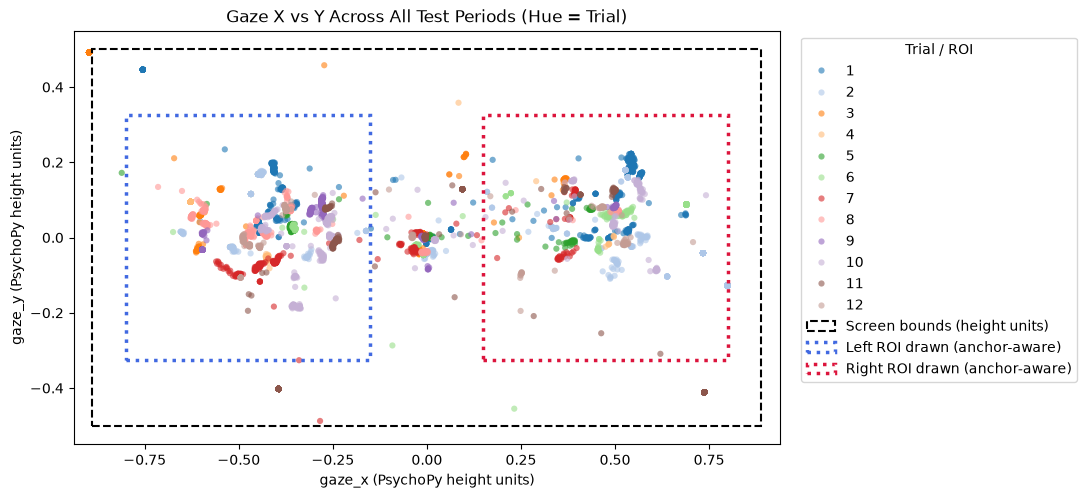

Points plotted: 5986
Trials represented: 12
Display: 1920x1080 (aspect=1.778)
Screen bounds (height units): x=[-0.889, 0.889], y=[-0.500, 0.500]

PsychoPy drawn ROI bounds (anchor-aware):
  Left  x=[-0.800, -0.150], y=[-0.325, 0.325]
  Right x=[0.150, 0.800], y=[-0.325, 0.325]


In [38]:
# Scatter of gaze positions (x, y) across all test periods, colored by trial
# Coordinates are interpreted in PsychoPy height units.

df_plot = df_test.copy()

df_plot['gaze_x'] = pd.to_numeric(df_plot['gaze_x'], errors='coerce')
df_plot['gaze_y'] = pd.to_numeric(df_plot['gaze_y'], errors='coerce')

# Assign test period index (1 or 2) within each trial and keep only test rows
# Label rows by test period using each period's own start/stop markers (bounded within the trial)
df_plot['test_period_num'] = 0
for trial, grp in df_plot.groupby('trial_number'):
    for period in (1, 2):
        start = grp.index[grp[f'Test_Event_{period}.started'].notna()]
        stop = grp.index[grp[f'Test_Event_{period}.stopped'].notna()]
        if len(start) and len(stop):
            df_plot.loc[start[0]:stop[0], 'test_period_num'] = period

df_plot = df_plot[df_plot['test_period_num'].between(1, 2)]

df_plot = df_plot.dropna(subset=['gaze_x', 'gaze_y', 'trial_number'])
df_plot['trial_number'] = df_plot['trial_number'].astype(int).astype(str)

# PsychoPy height-units bounds using your display resolution (1920 x 1080)
screen_width_px = 1920
screen_height_px = 1080
screen_aspect = screen_width_px / screen_height_px

y_min, y_max = -0.5, 0.5
x_half = 0.5 * screen_aspect
x_min, x_max = -x_half, x_half

fig, ax = plt.subplots(figsize=(11, 8))
sns.scatterplot(
    data=df_plot,
    x='gaze_x',
    y='gaze_y',
    hue='trial_number',
    palette='tab20',
    s=20,
    alpha=0.6,
    linewidth=0,
    ax=ax,
)

# Draw the visible screen area in height units
screen_rect = plt.Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    fill=False,
    edgecolor='black',
    linestyle='--',
    linewidth=1.5,
    label='Screen bounds (height units)',
)
ax.add_patch(screen_rect)

# ROI settings from Builder
roi_w, roi_h = 0.65, 0.65
left_pos = (-0.8, 0.0)
right_pos = (0.8, 0.0)

# Anchor-aware bounds as PsychoPy draws them:
# center-left: pos is the midpoint of the LEFT edge
left_drawn_x0 = left_pos[0]
left_drawn_x1 = left_pos[0] + roi_w
left_drawn_y0 = left_pos[1] - roi_h / 2
left_drawn_y1 = left_pos[1] + roi_h / 2

# center-right: pos is the midpoint of the RIGHT edge
right_drawn_x0 = right_pos[0] - roi_w
right_drawn_x1 = right_pos[0]
right_drawn_y0 = right_pos[1] - roi_h / 2
right_drawn_y1 = right_pos[1] + roi_h / 2

# Draw only PsychoPy-drawn ROI boundaries (anchor-aware)
left_roi_drawn = plt.Rectangle(
    (left_drawn_x0, left_drawn_y0),
    roi_w,
    roi_h,
    fill=False,
    edgecolor='royalblue',
    linestyle=':',
    linewidth=2.5,
    label='Left ROI drawn (anchor-aware)',
)
right_roi_drawn = plt.Rectangle(
    (right_drawn_x0, right_drawn_y0),
    roi_w,
    roi_h,
    fill=False,
    edgecolor='crimson',
    linestyle=':',
    linewidth=2.5,
    label='Right ROI drawn (anchor-aware)',
)
ax.add_patch(left_roi_drawn)
ax.add_patch(right_roi_drawn)

ax.set_title('Gaze X vs Y Across All Test Periods (Hue = Trial)')
ax.set_xlabel('gaze_x (PsychoPy height units)')
ax.set_ylabel('gaze_y (PsychoPy height units)')
ax.set_aspect('equal', adjustable='box')
ax.set_xlim(x_min - 0.05, x_max + 0.05)
ax.set_ylim(y_min - 0.05, y_max + 0.05)
ax.legend(title='Trial / ROI', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

print(f'Points plotted: {len(df_plot)}')
print(f'Trials represented: {df_plot["trial_number"].nunique()}')
print(f'Display: {screen_width_px}x{screen_height_px} (aspect={screen_aspect:.3f})')
print(f'Screen bounds (height units): x=[{x_min:.3f}, {x_max:.3f}], y=[{y_min:.3f}, {y_max:.3f}]')
print('')
print('PsychoPy drawn ROI bounds (anchor-aware):')
print(f'  Left  x=[{left_drawn_x0:.3f}, {left_drawn_x1:.3f}], y=[{left_drawn_y0:.3f}, {left_drawn_y1:.3f}]')
print(f'  Right x=[{right_drawn_x0:.3f}, {right_drawn_x1:.3f}], y=[{right_drawn_y0:.3f}, {right_drawn_y1:.3f}]')

Test Period 1: 3515 gaze samples across 12 trials
Test Period 2: 2471 gaze samples across 10 trials



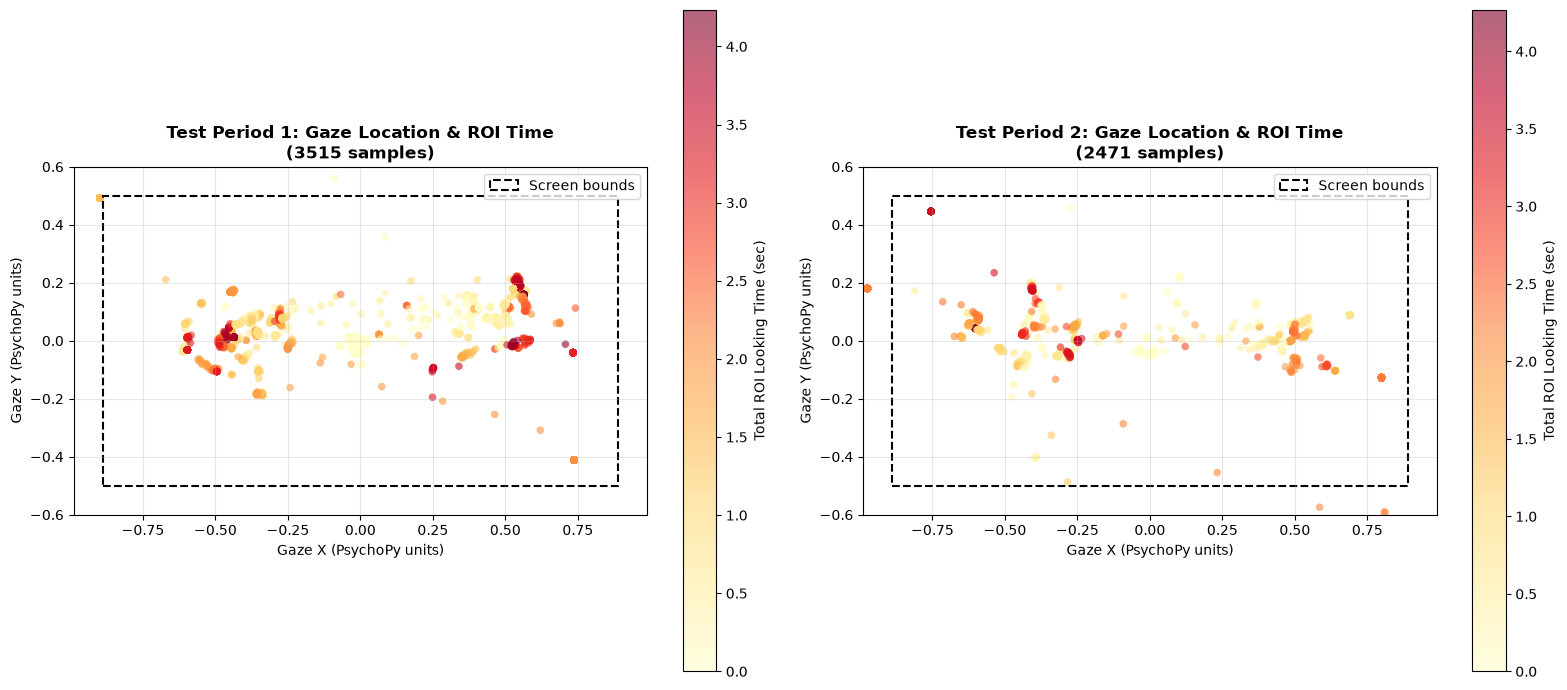

DATA QUALITY SUMMARY

TEST PERIOD 1:
  Total rows: 3642
  Rows with gaze data: 3515 (96.5%)
  Rows with ROI time data: 3642
  Max ROI time: 4.233 sec

TEST PERIOD 2:
  Total rows: 3654
  Rows with gaze data: 2471 (67.6%)
  Rows with ROI time data: 3642
  Max ROI time: 4.267 sec

Gaze samples per trial:

TEST PERIOD 1:
  Trial  1:  302 samples, final accumulated ROI time 4.23 sec
  Trial  2:  258 samples, final accumulated ROI time 3.10 sec
  Trial  3:  304 samples, final accumulated ROI time 1.42 sec
  Trial  4:  225 samples, final accumulated ROI time 0.15 sec
  Trial  5:  303 samples, final accumulated ROI time 1.73 sec
  Trial  6:  303 samples, final accumulated ROI time 0.90 sec
  Trial  7:  304 samples, final accumulated ROI time 2.32 sec
  Trial  8:  303 samples, final accumulated ROI time 3.92 sec
  Trial  9:  304 samples, final accumulated ROI time 3.23 sec
  Trial 10:  303 samples, final accumulated ROI time 2.60 sec
  Trial 11:  303 samples, final accumulated ROI time 2.05 se

In [39]:
# Data Quality Check: Gaze location and looking time by test period

# Prepare data for each test period
test_1_data = df_work[df_work['test_period_num'] == 1].copy()
test_2_data = df_work[df_work['test_period_num'] == 2].copy()

# Convert columns to numeric
for col in ['gaze_x', 'gaze_y', 'gaze_time_in_roi_left_test_1', 'gaze_time_in_roi_right_test_1', 
            'gaze_time_in_roi_left_test_2', 'gaze_time_in_roi_right_test_2']:
    test_1_data[col] = pd.to_numeric(test_1_data[col], errors='coerce')
    test_2_data[col] = pd.to_numeric(test_2_data[col], errors='coerce')

# For test_1, accumulate left+right ROI time as total looking time at ROI
test_1_data['total_roi_time'] = test_1_data['gaze_time_in_roi_left_test_1'] + test_1_data['gaze_time_in_roi_right_test_1']

# For test_2, accumulate left+right ROI time as total looking time at ROI
test_2_data['total_roi_time'] = test_2_data['gaze_time_in_roi_left_test_2'] + test_2_data['gaze_time_in_roi_right_test_2']

# Remove rows with missing gaze data
test_1_plot = test_1_data.dropna(subset=['gaze_x', 'gaze_y'])
test_2_plot = test_2_data.dropna(subset=['gaze_x', 'gaze_y'])

# Convert trial_number to string for hue coloring
test_1_plot['trial_str'] = test_1_plot['trial_number'].astype(int).astype(str)
test_2_plot['trial_str'] = test_2_plot['trial_number'].astype(int).astype(str)

print(f"Test Period 1: {len(test_1_plot)} gaze samples across {test_1_plot['trial_str'].nunique()} trials")
print(f"Test Period 2: {len(test_2_plot)} gaze samples across {test_2_plot['trial_str'].nunique()} trials")
print()

# Create side-by-side figures
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# ===== TEST PERIOD 1 =====
ax1 = axes[0]
if len(test_1_plot) > 0:
    scatter1 = ax1.scatter(
        test_1_plot['gaze_x'],
        test_1_plot['gaze_y'],
        c=test_1_plot['total_roi_time'],
        s=30,
        alpha=0.6,
        cmap='YlOrRd',
        edgecolors='none'
    )
    cbar1 = plt.colorbar(scatter1, ax=ax1)
    cbar1.set_label('Total ROI Looking Time (sec)')
    
    ax1.set_title(f'Test Period 1: Gaze Location & ROI Time\n({len(test_1_plot)} samples)', fontsize=12, fontweight='bold')
else:
    ax1.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax1.transAxes)
    ax1.set_title('Test Period 1: No Data')

ax1.set_xlabel('Gaze X (PsychoPy units)')
ax1.set_ylabel('Gaze Y (PsychoPy units)')
ax1.grid(True, alpha=0.3)
ax1.set_aspect('equal')

# Draw screen bounds
screen_rect1 = plt.Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    fill=False,
    edgecolor='black',
    linestyle='--',
    linewidth=1.5,
    label='Screen bounds'
)
ax1.add_patch(screen_rect1)
ax1.set_xlim(x_min - 0.1, x_max + 0.1)
ax1.set_ylim(y_min - 0.1, y_max + 0.1)
ax1.legend()

# ===== TEST PERIOD 2 =====
ax2 = axes[1]
if len(test_2_plot) > 0:
    scatter2 = ax2.scatter(
        test_2_plot['gaze_x'],
        test_2_plot['gaze_y'],
        c=test_2_plot['total_roi_time'],
        s=30,
        alpha=0.6,
        cmap='YlOrRd',
        edgecolors='none'
    )
    cbar2 = plt.colorbar(scatter2, ax=ax2)
    cbar2.set_label('Total ROI Looking Time (sec)')
    
    ax2.set_title(f'Test Period 2: Gaze Location & ROI Time\n({len(test_2_plot)} samples)', fontsize=12, fontweight='bold')
else:
    ax2.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax2.transAxes)
    ax2.set_title('Test Period 2: No Data')

ax2.set_xlabel('Gaze X (PsychoPy units)')
ax2.set_ylabel('Gaze Y (PsychoPy units)')
ax2.grid(True, alpha=0.3)
ax2.set_aspect('equal')

# Draw screen bounds
screen_rect2 = plt.Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    fill=False,
    edgecolor='black',
    linestyle='--',
    linewidth=1.5,
    label='Screen bounds'
)
ax2.add_patch(screen_rect2)
ax2.set_xlim(x_min - 0.1, x_max + 0.1)
ax2.set_ylim(y_min - 0.1, y_max + 0.1)
ax2.legend()

plt.tight_layout()
plt.show()

# Data quality summary
print("=" * 80)
print("DATA QUALITY SUMMARY")
print("=" * 80)
print()
print("TEST PERIOD 1:")
print(f"  Total rows: {len(test_1_data)}")
print(f"  Rows with gaze data: {len(test_1_plot)} ({100*len(test_1_plot)/len(test_1_data):.1f}%)")
print(f"  Rows with ROI time data: {test_1_data['total_roi_time'].notna().sum()}")
print(f"  Max ROI time: {test_1_data['total_roi_time'].max():.3f} sec")
print()

print("TEST PERIOD 2:")
print(f"  Total rows: {len(test_2_data)}")
print(f"  Rows with gaze data: {len(test_2_plot)} ({100*len(test_2_plot)/len(test_2_data):.1f}%)")
print(f"  Rows with ROI time data: {test_2_data['total_roi_time'].notna().sum()}")
print(f"  Max ROI time: {test_2_data['total_roi_time'].max():.3f} sec")
print()

# Per-trial breakdown
print("Gaze samples per trial:")
print()
print("TEST PERIOD 1:")
for trial in sorted(test_1_plot['trial_number'].unique()):
    count = len(test_1_plot[test_1_plot['trial_number'] == trial])
    roi_time = test_1_data.loc[test_1_data['trial_number'] == trial, 'total_roi_time'].max()
    print(f"  Trial {int(trial):2d}: {count:4d} samples, final accumulated ROI time {roi_time:.2f} sec")
print()

print("TEST PERIOD 2:")
for trial in sorted(test_2_plot['trial_number'].unique()):
    count = len(test_2_plot[test_2_plot['trial_number'] == trial])
    roi_time = test_2_data.loc[test_2_data['trial_number'] == trial, 'total_roi_time'].max()
    print(f"  Trial {int(trial):2d}: {count:4d} samples, final accumulated ROI time {roi_time:.2f} sec")